# 05 - Idée 2 : gradient boosting

Question : un modèle à arbres (LightGBM) trouve-t-il du signal que la logistique ne voit pas ?

Trois variantes, décidées avant de regarder les résultats :
- **A** : LightGBM sur les mêmes features que `logit_alloc` (baseline + allocation). Isole l'effet du changement de modèle.
- **B** : LightGBM sur des features plus riches (`utils.rich_features`) : lags 2 à 10, rangs par date des volumes signés,
  du rendement d'hier et de la vol. Ce sont des informations qu'un arbre exploite mieux qu'une logistique.
- **C** : moyenne des probabilités de `logit_alloc` et de B.

Référence : `logit_alloc` (51,89 % sur les dates récentes). Règle : gain moyen > 2 erreurs-types, sur les mêmes plis.
Compter 5 à 10 minutes pour l'ensemble du notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from pathlib import Path
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

import utils
from utils import compare

SEED = 42
plt.rcParams.update({'figure.figsize': (9, 3.4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .25, 'font.size': 10})
BLUE, GREY = '#2a6fdb', '#8a8f98'

X, y, Xt = utils.load_data()
ch, folds = utils.load_split()
recent = utils.recent_regime(X, ch)
is_recent = X.TS.map(recent).to_numpy()
up = (y > 0).to_numpy()
masks = [(X.TS.isin(f['train']).to_numpy(), X.TS.isin(f['val']).to_numpy()) for f in folds]
reference = utils.journal_scores('logit_alloc')

ALLOCS = np.array(sorted(X.ALLOCATION.unique()))
alloc_code = lambda df: pd.Series(np.arange(len(ALLOCS)), index=ALLOCS)[df.ALLOCATION].to_numpy()
def alloc_dummies(df):
    return sparse.csr_matrix((np.ones(len(df)), (np.arange(len(df)), alloc_code(df))), shape=(len(df), len(ALLOCS)))

F = utils.baseline_features(X)
R = utils.rich_features(X)
D = alloc_dummies(X)
print('features baseline :', F.shape[1], '| features riches :', R.shape[1])

features baseline : 10 | features riches : 26


In [2]:
def scores_from_oof(prob):
    # accuracies par pli à partir de probabilités hors échantillon
    rec, allv = [], []
    for tr, va in masks:
        hit = (prob[va] > .5) == up[va]
        rec.append(hit[is_recent[va]].mean())
        allv.append(hit.mean())
    return np.array(rec), np.array(allv)

def summary_row(name, scores):
    r, a = scores
    c = compare(r, reference)
    return {'modèle': name, 'récentes': r.mean(), 'toutes': a.mean(), 'gain': c['mean_diff'],
            'erreur-type': c['se'], 't': c['t'], 'plis gagnés': int((r > reference).sum()), 'retenu': c['retenu']}

# probabilités hors échantillon de la référence, nécessaires pour la variante C
oof_logit = np.full(len(X), np.nan)
for tr, va in masks:
    s = StandardScaler().fit(F[tr])
    model = LogisticRegression(C=0.003, max_iter=3000).fit(sparse.hstack([s.transform(F[tr]), D[tr]]).tocsr(), up[tr])
    oof_logit[va] = model.predict_proba(sparse.hstack([s.transform(F[va]), D[va]]).tocsr())[:, 1]
print('logit_alloc recalculé :', scores_from_oof(oof_logit)[0].mean().round(4))

logit_alloc recalculé : 0.5189


## 1. Réglages du LightGBM

Avec un signal aussi faible, le risque principal d'un boosting est d'apprendre du bruit. Les réglages vont tous dans le sens de la prudence :
- arbres peu profonds (`max_depth=3`, 8 feuilles) : interactions d'ordre 2 ou 3 au plus ;
- au moins 2 000 lignes par feuille, pénalité L2, sous-échantillonnage des lignes et des colonnes ;
- 500 arbres avec un pas de 0,02, **fixés à l'avance**. On ne règle rien sur les plis de validation : chaque réglage
  testé serait un essai de plus, et les scores deviendraient optimistes.

L'allocation est passée comme variable catégorielle : LightGBM la traite nativement, avec un lissage (`cat_smooth`)
qui joue le même rôle que la régularisation des effets fixes.

In [3]:
PARAMS = dict(objective='binary', verbosity=-1, seed=SEED, max_depth=3, num_leaves=8, learning_rate=.02,
              min_data_in_leaf=2000, feature_fraction=.8, bagging_fraction=.7, bagging_freq=1,
              lambda_l2=10, cat_smooth=50)
N_ROUNDS = 500

def lgbm_oof(M):
    G = M.copy()
    G['alloc'] = alloc_code(X)
    oof, importances = np.full(len(X), np.nan), []
    for tr, va in masks:
        model = lgb.train(PARAMS, lgb.Dataset(G[tr], label=up[tr].astype(int), categorical_feature=['alloc']),
                          num_boost_round=N_ROUNDS)
        oof[va] = model.predict(G[va])
        importances.append(pd.Series(model.feature_importance('gain'), index=G.columns))
    return oof, pd.concat(importances, axis=1).mean(axis=1)

oof_a, imp_a = lgbm_oof(F)
oof_b, imp_b = lgbm_oof(R)
oof_c = (oof_logit + oof_b) / 2

## 2. Résultats

In [4]:
scores = {'A LightGBM, mêmes features': scores_from_oof(oof_a),
          'B LightGBM, features riches': scores_from_oof(oof_b),
          'C moyenne logit_alloc + B': scores_from_oof(oof_c)}
for name, key in zip(scores, ['lgbm_same', 'lgbm_rich', 'blend_logit_lgbm']):
    _ = utils.log_result(key, *scores[name], note=name)

pd.DataFrame([summary_row(n, s) for n, s in scores.items()]).set_index('modèle').round(4)

,récentes,toutes,gain,erreur-type,t,plis gagnés,retenu
modèle,,,,,,,
"A LightGBM, mêmes features",0.5201,0.5248,0.0012,0.0015,0.8069,4,False
"B LightGBM, features riches",0.5202,0.5250,0.0013,0.0014,0.9243,4,False
C moyenne logit_alloc + B,0.5203,0.5252,0.0014,0.0007,1.9693,6,False


Lecture :
- Les trois variantes font un peu mieux que la logistique, de +0,12 à +0,14 point, mais **aucune ne passe la règle**.
  A et B gagnent sur la moitié des plis seulement : leur avantage n'est pas régulier.
- Les features riches n'apportent rien au boosting (B ≈ A). Les lags lointains et les volumes ne contiennent pas
  d'information exploitable au-delà de ce que résument déjà nos features.
- Le mélange C est le plus stable des trois : il gagne sur 6 plis sur 8, avec une erreur-type divisée par deux.
  Son t (1,97) est juste sous le seuil de 2 : c'est un cas limite, qu'on ne compte pas comme un gain.
  C'est le comportement classique d'un mélange de deux modèles différents : il ne trouve pas de nouveau signal,
  il réduit la variance des erreurs.

Conclusion : **le boosting n'est pas retenu comme nouvelle référence.** Le signal est essentiellement linéaire, et un modèle
non linéaire bien bridé finit par faire la même chose qu'une logistique. Le mélange C reste un candidat raisonnable pour
la soumission finale, puisque mélanger deux modèles fait rarement baisser le score, mais il n'est pas prouvé.

## 3. Ce que le boosting utilise

Importance par gain (amélioration totale de la perte apportée par chaque feature), moyenne sur les 8 plis, modèle B.

{'log_turnover': 0.016, 'ret8_z': 0.017, 'mean5_z': 0.017, 'ret3_z': 0.019, 'sv1_day': 0.019, 'ret2_z': 0.022, 'ret1_rank': 0.026, 'mkt_ret1': 0.041, 'ret1_z': 0.139, 'alloc': 0.562}


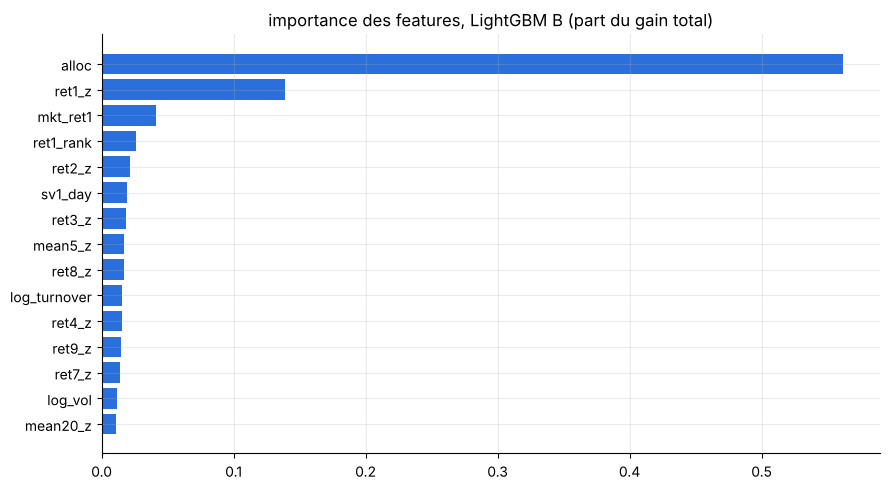

In [5]:
imp = (imp_b / imp_b.sum()).sort_values()
print(imp.tail(10).round(3).to_dict())
plt.figure(figsize=(9, 5))
plt.barh(imp.index[-15:], imp.values[-15:], color=BLUE)
plt.title('importance des features, LightGBM B (part du gain total)')
plt.tight_layout()
plt.show()

L'allocation arrive en tête avec plus de la moitié du gain, puis `ret1_z` loin devant le reste. Deux précautions de lecture :
l'importance par gain favorise mécaniquement une variable catégorielle à 278 modalités (chaque coupure peut séparer des
groupes d'allocations sur mesure), donc la part de l'allocation est surestimée ; et une importance élevée ne dit pas que la
variable améliore l'accuracy hors échantillon. Le reste confirme l'histoire de la logistique : le rendement d'hier sous ses
différentes formes, puis le mouvement de marché, le jour SV_1 et le turnover. Les volumes signés n'apparaissent pas dans le top 10.

## 4. Fichier de soumission du mélange (optionnel)

On le produit pour pouvoir le soumettre si on veut un point de contrôle, sans en faire la nouvelle référence.
Les deux modèles sont réentraînés sur tout le train.

In [6]:
s_all = StandardScaler().fit(F)
logit_final = LogisticRegression(C=0.003, max_iter=3000).fit(sparse.hstack([s_all.transform(F), D]).tocsr(), up)
G = R.copy(); G['alloc'] = alloc_code(X)
lgbm_final = lgb.train(PARAMS, lgb.Dataset(G, label=up.astype(int), categorical_feature=['alloc']), num_boost_round=N_ROUNDS)

Ft, Rt = utils.baseline_features(Xt), utils.rich_features(Xt)
Gt = Rt.copy(); Gt['alloc'] = alloc_code(Xt)
p_test = (logit_final.predict_proba(sparse.hstack([s_all.transform(Ft), alloc_dummies(Xt)]).tocsr())[:, 1]
          + lgbm_final.predict(Gt)) / 2

sample = pd.read_csv(utils.find_data_dir() / 'sample_submission.csv', index_col='ROW_ID')
submission = pd.DataFrame({sample.columns[0]: (p_test > .5).astype(int)}, index=Xt.index).loc[sample.index]
submission.index.name = 'ROW_ID'
Path('submissions').mkdir(exist_ok=True)
submission.to_csv('submissions/03_blend_logit_lgbm.csv')
print(submission.shape, '| part de 1 :', round(submission.iloc[:, 0].mean(), 3))

(31870, 1) | part de 1 : 0.575


## Bilan

| | dates récentes | gain vs `logit_alloc` | plis gagnés |
|---|---|---|---|
| `logit_alloc` (référence) | 51,89 % | | |
| A LightGBM, mêmes features | 52,01 % | +0,12 | 4/8 |
| B LightGBM, features riches | 52,02 % | +0,13 | 4/8 |
| C moyenne logit + B | 52,03 % | +0,14 (t = 1,97) | 6/8 |

Aucune variante ne passe la règle. Le changement de modèle n'est pas le levier principal sur ce problème :
le signal disponible dans les features actuelles est presque entièrement linéaire. Pour progresser, il faut
une **nouvelle source d'information**, pas un modèle plus flexible.